# CS 521 HW4, Problem 1: Interval Bound Propagation (IBP) Training

**Network.** Normalize -> Flatten -> 3 x (Linear(., 50) + ReLU) -> Linear(50, 10), trained on MNIST with cross-entropy.

**Part (a).** IBP training (Gowal et al. 2019) with the two schedules from the paper:
- the weight $\kappa$ of Equation 12 goes from 1 to 0.5,
- the training radius $\epsilon_{train}$ goes from 0 to 0.1.

The loss is $L_{IBP} = \kappa\,CE(z_K, y) + (1-\kappa)\,CE(\hat z_K(\epsilon_{train}), y)$.
Following Equation 9 of the paper, the last linear layer is merged into the robustness specification, so the worst-case logits are $\hat z_K = -\underline{(f_y - f_j)}$ for $j \ne y$ and $\hat z_{K,y} = 0$.
We compare standard accuracy, PGD robust accuracy and training time against a standardly trained network with the same architecture and epochs.

**Part (b).** Verified accuracy with the box (interval) verifier from HW2, for 10 values of $\epsilon_{test}$ from 0.01 to 0.1. For balls that are not certified we search for adversarial examples with PGD and analyse them.

In [1]:
import time, json, os
from collections import Counter

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu'))
print('device:', device)

SEED = 0
torch.manual_seed(SEED); np.random.seed(SEED)

def sync():
    if device.type == 'cuda':
        torch.cuda.synchronize()

device: cpu


## Data

Same MNIST setup as HW2: pixels stay in $[0,1]$ and the mean/std normalization is a layer *inside* the network, so every $\epsilon$ in this notebook is measured in pixel space.

In [2]:
MEAN, STD = 0.1307, 0.3081
BATCH = 128

tf = transforms.ToTensor()
train_set = datasets.MNIST('./mnist_data', train=True, download=True, transform=tf)
test_set = datasets.MNIST('./mnist_data', train=False, download=True, transform=tf)
train_loader = DataLoader(train_set, batch_size=BATCH, shuffle=True)
test_loader = DataLoader(test_set, batch_size=1000, shuffle=False)

Xte = torch.cat([x for x, _ in test_loader]).to(device)
Yte = torch.cat([y for _, y in test_loader]).to(device)
print(Xte.shape, Yte.shape)

100%|██████████| 9.91M/9.91M [00:00<00:00, 115MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 3.26MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 28.4MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.14MB/s]


torch.Size([10000, 1, 28, 28]) torch.Size([10000])


## Model

In [3]:
class Normalize(nn.Module):
    def forward(self, x):
        return (x - MEAN) / STD

def make_model():
    layers, d = [Normalize(), nn.Flatten()], 28 * 28
    for _ in range(3):
        layers += [nn.Linear(d, 50), nn.ReLU()]
        d = 50
    layers.append(nn.Linear(d, 10))
    return nn.Sequential(*layers).to(device)

print(make_model())

Sequential(
  (0): Normalize()
  (1): Flatten(start_dim=1, end_dim=-1)
  (2): Linear(in_features=784, out_features=50, bias=True)
  (3): ReLU()
  (4): Linear(in_features=50, out_features=50, bias=True)
  (5): ReLU()
  (6): Linear(in_features=50, out_features=50, bias=True)
  (7): ReLU()
  (8): Linear(in_features=50, out_features=10, bias=True)
)


## Interval bound propagation

For an image $x$ and radius $\epsilon$ the input box is $[\max(x-\epsilon,0),\ \min(x+\epsilon,1)]$. With center $\mu$ and radius $r$ of the current box:

- Normalize is increasing, so the bounds are normalized directly.
- Linear layer $Wh+b$: $\mu' = W\mu + b$, $r' = |W|\,r$.
- ReLU is monotone: $[\max(l,0),\ \max(u,0)]$.
- **Specification layer.** For the label $y$, row $j$ of the merged last layer is $D_j = W_y - W_j$, $d_j = b_y - b_j$, so it computes $f_y - f_j$ directly. Its lower bound is $D_j\mu + d_j - |D_j|\,r$. Row $y$ is exactly 0.

The IBP worst-case logits are $\hat z_K = -\text{lb}$ (the upper bound of $f_j - f_y$ for $j \ne y$ and 0 for $y$). The same function is the box verifier of HW2 (extended from one hidden layer to three): an image is verified iff all lower bounds are $\ge 0$.

In [4]:
def margin_lower_bounds(model, x, y, eps):
    linears = [m for m in model if isinstance(m, nn.Linear)]
    lo = ((x - eps).clamp(0, 1).flatten(1) - MEAN) / STD
    hi = ((x + eps).clamp(0, 1).flatten(1) - MEAN) / STD
    for lin in linears[:-1]:
        mu, r = (hi + lo) / 2, (hi - lo) / 2
        mu, r = F.linear(mu, lin.weight, lin.bias), F.linear(r, lin.weight.abs())
        lo, hi = F.relu(mu - r), F.relu(mu + r)
    W, b = linears[-1].weight, linears[-1].bias
    D = W[y].unsqueeze(1) - W.unsqueeze(0)
    d = b[y].unsqueeze(1) - b.unsqueeze(0)
    mu, r = (hi + lo) / 2, (hi - lo) / 2
    return torch.einsum('bjk,bk->bj', D, mu) + d - torch.einsum('bjk,bk->bj', D.abs(), r)

def ibp_loss(model, x, y, eps, kappa):
    z = model(x)
    ce = F.cross_entropy(z, y)
    if eps == 0:
        return ce, ce, ce
    z_hat = -margin_lower_bounds(model, x, y, eps)
    rob = F.cross_entropy(z_hat, y)
    return kappa * ce + (1 - kappa) * rob, ce, rob

@torch.no_grad()
def verified_mask(model, X, Y, eps, bs=1000):
    out = []
    for i in range(0, len(X), bs):
        lb = margin_lower_bounds(model, X[i:i+bs], Y[i:i+bs], eps)
        out.append(lb.min(dim=1).values >= 0)
    return torch.cat(out)

@torch.no_grad()
def clean_accuracy(model, X, Y, bs=1000):
    model.eval()
    return 100 * sum((model(X[i:i+bs]).argmax(1) == Y[i:i+bs]).sum().item() for i in range(0, len(X), bs)) / len(X)

## PGD attack ($\ell_\infty$)

Standard PGD with a random start, step size $2.5\,\epsilon/\text{steps}$ and projection onto the $\epsilon$-ball intersected with $[0,1]$. With restarts, an example counts as broken if any restart fools the network.

In [5]:
def pgd_attack(model, x, y, eps, steps=50, restarts=2):
    if eps == 0:
        return x.clone()
    alpha = 2.5 * eps / steps
    best, fooled = x.clone(), torch.zeros(len(x), dtype=torch.bool, device=x.device)
    for _ in range(restarts):
        xa = (x + (torch.rand_like(x) * 2 - 1) * eps).clamp(0, 1)
        for _ in range(steps):
            xa.requires_grad_(True)
            g, = torch.autograd.grad(F.cross_entropy(model(xa), y), xa)
            xa = xa.detach() + alpha * g.sign()
            xa = torch.min(torch.max(xa, x - eps), x + eps).clamp(0, 1)
        wrong = model(xa).argmax(1) != y
        upd = wrong & ~fooled
        best[upd] = xa[upd]
        fooled |= wrong
        best[~fooled] = xa[~fooled]
    return best.detach()

def pgd_accuracy(model, X, Y, eps, bs=1000, **kw):
    model.eval()
    correct = 0
    for i in range(0, len(X), bs):
        xa = pgd_attack(model, X[i:i+bs], Y[i:i+bs], eps, **kw)
        with torch.no_grad():
            correct += (model(xa).argmax(1) == Y[i:i+bs]).sum().item()
    return 100 * correct / len(X)

## Part (a): training

**Schedules (per training step).** For the first 10% of the steps $\epsilon_{train}=0$ and $\kappa=1$ (plain training warm-up). Over the next 50% of the steps both are ramped linearly, $\epsilon_{train}: 0 \to 0.1$ and $\kappa: 1 \to 0.5$. For the last 40% they stay at $\epsilon_{train}=0.1$, $\kappa=0.5$. Both models use Adam (lr $10^{-3}$, decayed by 10x after 75% of the epochs) and the same number of epochs.

In [6]:
EPOCHS = 40
EPS_TRAIN, KAPPA_END = 0.1, 0.5
WARM, RAMP_END = 0.1, 0.6

steps_per_epoch = len(train_loader)
total_steps = EPOCHS * steps_per_epoch

def ramp(step):
    s0, s1 = WARM * total_steps, RAMP_END * total_steps
    return float(min(1.0, max(0.0, (step - s0) / (s1 - s0))))

def eps_schedule(step):   return EPS_TRAIN * ramp(step)
def kappa_schedule(step): return 1.0 - (1.0 - KAPPA_END) * ramp(step)

def make_opt(model):
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    sched = torch.optim.lr_scheduler.MultiStepLR(opt, milestones=[int(0.75 * EPOCHS)], gamma=0.1)
    return opt, sched

def train(model, mode):
    opt, sched = make_opt(model)
    step, hist = 0, []
    sync(); t0 = time.time()
    for ep in range(EPOCHS):
        model.train()
        tot = {'loss': 0., 'ce': 0., 'rob': 0.}; n = 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            if mode == 'ibp':
                eps, kappa = eps_schedule(step), kappa_schedule(step)
                loss, ce, rob = ibp_loss(model, x, y, eps, kappa)
            else:
                eps, kappa = 0.0, 1.0
                ce = F.cross_entropy(model(x), y); loss, rob = ce, ce
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            step += 1
            tot['loss'] += loss.item(); tot['ce'] += ce.item(); tot['rob'] += rob.item(); n += 1
        sched.step()
        acc = clean_accuracy(model, Xte, Yte)
        hist.append(dict(epoch=ep + 1, eps=eps, kappa=kappa, loss=tot['loss'] / n, ce=tot['ce'] / n, rob=tot['rob'] / n, test_acc=acc))
        if (ep + 1) % 5 == 0 or ep == 0:
            print(f"[{mode}] epoch {ep+1:3d}  eps_train={eps:.3f} kappa={kappa:.2f}  loss={tot['loss']/n:.4f}  CE={tot['ce']/n:.4f}  robust CE={tot['rob']/n:.4f}  test acc={acc:.2f}%")
    sync()
    return time.time() - t0, hist

torch.manual_seed(SEED)
std_model = make_model()
t_std, hist_std = train(std_model, 'standard')
print(f'standard training time: {t_std:.1f}s')

[standard] epoch   1  eps_train=0.000 kappa=1.00  loss=0.4190  CE=0.4190  robust CE=0.4190  test acc=94.05%
[standard] epoch   5  eps_train=0.000 kappa=1.00  loss=0.0867  CE=0.0867  robust CE=0.0867  test acc=96.47%
[standard] epoch  10  eps_train=0.000 kappa=1.00  loss=0.0455  CE=0.0455  robust CE=0.0455  test acc=97.21%
[standard] epoch  15  eps_train=0.000 kappa=1.00  loss=0.0281  CE=0.0281  robust CE=0.0281  test acc=97.12%
[standard] epoch  20  eps_train=0.000 kappa=1.00  loss=0.0213  CE=0.0213  robust CE=0.0213  test acc=97.48%
[standard] epoch  25  eps_train=0.000 kappa=1.00  loss=0.0139  CE=0.0139  robust CE=0.0139  test acc=97.30%
[standard] epoch  30  eps_train=0.000 kappa=1.00  loss=0.0092  CE=0.0092  robust CE=0.0092  test acc=97.07%
[standard] epoch  35  eps_train=0.000 kappa=1.00  loss=0.0007  CE=0.0007  robust CE=0.0007  test acc=97.78%
[standard] epoch  40  eps_train=0.000 kappa=1.00  loss=0.0003  CE=0.0003  robust CE=0.0003  test acc=97.86%
standard training time: 314.

In [7]:
torch.manual_seed(SEED)
ibp_model = make_model()
t_ibp, hist_ibp = train(ibp_model, 'ibp')
print(f'IBP training time: {t_ibp:.1f}s  ({t_ibp / t_std:.2f}x the standard training time)')

torch.save(std_model.state_dict(), 'std_model.pt'); torch.save(ibp_model.state_dict(), 'ibp_model.pt')

[ibp] epoch   1  eps_train=0.000 kappa=1.00  loss=0.4190  CE=0.4190  robust CE=0.4190  test acc=94.05%
[ibp] epoch   5  eps_train=0.005 kappa=0.98  loss=0.1137  CE=0.0892  robust CE=1.5689  test acc=96.58%
[ibp] epoch  10  eps_train=0.030 kappa=0.85  loss=0.1886  CE=0.1012  robust CE=0.7368  test acc=97.08%
[ibp] epoch  15  eps_train=0.055 kappa=0.73  loss=0.2648  CE=0.1158  robust CE=0.6834  test acc=96.47%
[ibp] epoch  20  eps_train=0.080 kappa=0.60  loss=0.3896  CE=0.1408  robust CE=0.7829  test acc=95.75%
[ibp] epoch  25  eps_train=0.100 kappa=0.50  loss=0.5432  CE=0.1803  robust CE=0.9062  test acc=94.66%
[ibp] epoch  30  eps_train=0.100 kappa=0.50  loss=0.4949  CE=0.1837  robust CE=0.8060  test acc=94.67%
[ibp] epoch  35  eps_train=0.100 kappa=0.50  loss=0.4495  CE=0.1773  robust CE=0.7217  test acc=94.83%
[ibp] epoch  40  eps_train=0.100 kappa=0.50  loss=0.4459  CE=0.1758  robust CE=0.7161  test acc=94.87%
IBP training time: 400.5s  (1.27x the standard training time)


### Part (a) results: standard accuracy, PGD robust accuracy and training time

In [8]:
EPS_ATTACK = 0.1
torch.manual_seed(SEED)
rows = []
for name, m, t in [('standard', std_model, t_std), ('IBP', ibp_model, t_ibp)]:
    rows.append((name, clean_accuracy(m, Xte, Yte), pgd_accuracy(m, Xte, Yte, 0.05), pgd_accuracy(m, Xte, Yte, EPS_ATTACK), t))

print(f"{'model':10s} {'clean acc':>10s} {'PGD eps=0.05':>13s} {'PGD eps=0.10':>13s} {'train time':>11s}")
for r in rows:
    print(f"{r[0]:10s} {r[1]:9.2f}% {r[2]:12.2f}% {r[3]:12.2f}% {r[4]:10.1f}s")
print(f'\nIBP training takes {t_ibp / t_std:.2f}x as long as standard training for the same number of epochs.')
print(f'(PGD: 50 steps, 2 restarts, full 10,000-image test set)')

model       clean acc  PGD eps=0.05  PGD eps=0.10  train time
standard       97.86%        53.53%         7.35%      314.9s
IBP            94.87%        90.96%        85.46%      400.5s

IBP training takes 1.27x as long as standard training for the same number of epochs.
(PGD: 50 steps, 2 restarts, full 10,000-image test set)


## Part (b): verified accuracy and adversarial examples

The verified accuracy is the percentage of test images for which the box verifier proves that the label cannot change in the $\ell_\infty$ ball of radius $\epsilon_{test}$ (a verified image is always classified correctly, because the center of the ball is in the ball). The PGD accuracy is an **upper bound** on the true robust accuracy, and the verified accuracy is a **lower bound**, so we always expect verified $\le$ true robust $\le$ PGD.

As a safety check, the last column counts verified images that PGD manages to break. A sound verifier gives 0.

In [9]:
EPS_TEST = np.linspace(0.01, 0.1, 10)
torch.manual_seed(SEED)
results = {'eps': [float(e) for e in EPS_TEST]}
for name, m in [('standard', std_model), ('IBP', ibp_model)]:
    m.eval(); ver, pgd, viol = [], [], []
    for e in EPS_TEST:
        vm = verified_mask(m, Xte, Yte, float(e))
        ver.append(100 * vm.float().mean().item())
        xa = torch.cat([pgd_attack(m, Xte[i:i+1000], Yte[i:i+1000], float(e)) for i in range(0, len(Xte), 1000)])
        with torch.no_grad():
            broken = torch.cat([m(xa[i:i+1000]).argmax(1) != Yte[i:i+1000] for i in range(0, len(xa), 1000)])
        pgd.append(100 * (~broken).float().mean().item())
        viol.append(int((vm & broken).sum().item()))
    results[name] = dict(verified=ver, pgd=pgd, violations=viol)

for name in ['standard', 'IBP']:
    print(f'\n{name} model (clean accuracy {clean_accuracy(std_model if name == "standard" else ibp_model, Xte, Yte):.2f}%)')
    print(f"{'eps_test':>9s} {'verified acc':>13s} {'PGD acc':>9s} {'gap':>7s} {'verified images broken by PGD':>31s}")
    r = results[name]
    for e, v, p, k in zip(EPS_TEST, r['verified'], r['pgd'], r['violations']):
        print(f'{e:9.2f} {v:12.2f}% {p:8.2f}% {p - v:6.2f}% {k:31d}')

json.dump(dict(results=results, t_std=t_std, t_ibp=t_ibp), open('results.json', 'w'), indent=1)


standard model (clean accuracy 97.86%)
 eps_test  verified acc   PGD acc     gap   verified images broken by PGD
     0.01         0.00%    95.21%  95.21%                               0
     0.02         0.00%    90.74%  90.74%                               0
     0.03         0.00%    82.25%  82.25%                               0
     0.04         0.00%    69.22%  69.22%                               0
     0.05         0.00%    53.68%  53.68%                               0
     0.06         0.00%    39.17%  39.17%                               0
     0.07         0.00%    27.10%  27.10%                               0
     0.08         0.00%    17.63%  17.63%                               0
     0.09         0.00%    11.64%  11.64%                               0
     0.10         0.00%     7.29%   7.29%                               0

IBP model (clean accuracy 94.87%)
 eps_test  verified acc   PGD acc     gap   verified images broken by PGD
     0.01        94.14%    94.25%   0

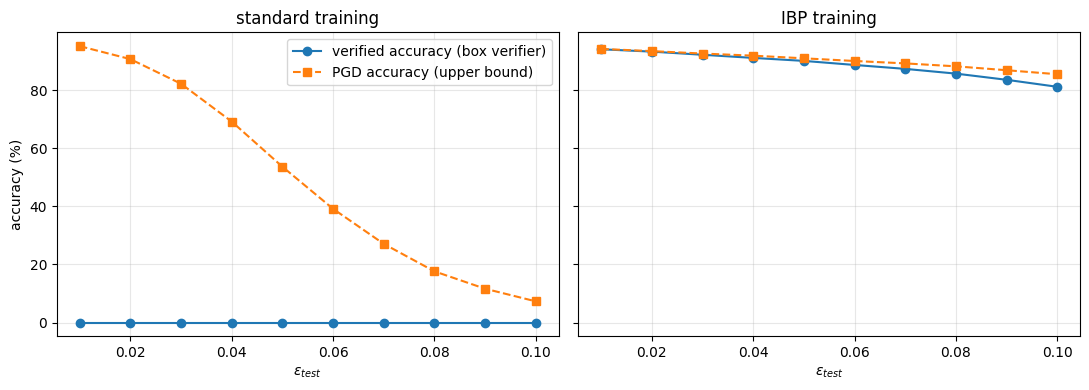

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, name in zip(ax, ['standard', 'IBP']):
    a.plot(EPS_TEST, results[name]['verified'], 'o-', label='verified accuracy (box verifier)')
    a.plot(EPS_TEST, results[name]['pgd'], 's--', label='PGD accuracy (upper bound)')
    a.set_title(f'{name} training'); a.set_xlabel(r'$\epsilon_{test}$'); a.grid(alpha=.3)
ax[0].set_ylabel('accuracy (%)'); ax[0].legend()
plt.tight_layout(); plt.savefig('verified_accuracy.png', dpi=150); plt.show()

### Soundness check of the verifier

For verified images, no point of the ball may change the prediction, and the computed lower bound must never exceed the true margin $f_y - f_j$. We test random points and box corners (every pixel pushed to $x\pm\epsilon$).

In [11]:
@torch.no_grad()
def soundness_check(model, eps, n_img=300, n_rand=100, n_corner=50):
    vm = verified_mask(model, Xte, Yte, eps)
    idx = vm.nonzero().flatten()[:n_img]
    x, y = Xte[idx], Yte[idx]
    lb = margin_lower_bounds(model, x, y, eps)
    bad_pred = bad_bound = 0
    for kind, n in [('rand', n_rand), ('corner', n_corner)]:
        for _ in range(n):
            s = (torch.rand_like(x) * 2 - 1) if kind == 'rand' else torch.sign(torch.rand_like(x) - .5)
            xp = (x + eps * s).clamp(0, 1)
            z = model(xp)
            margin = z.gather(1, y[:, None]) - z
            bad_pred += (z.argmax(1) != y).sum().item()
            bad_bound += (lb > margin + 1e-4).sum().item()
    print(f'eps={eps:.2f}: {len(idx)} verified images x {n_rand + n_corner} points -> '
          f'{bad_pred} prediction changes, {bad_bound} bound violations')

for e in [0.02, 0.05, 0.1]:
    soundness_check(ibp_model, e)

eps=0.02: 300 verified images x 150 points -> 0 prediction changes, 0 bound violations
eps=0.05: 300 verified images x 150 points -> 0 prediction changes, 0 bound violations
eps=0.10: 300 verified images x 150 points -> 0 prediction changes, 0 bound violations


### Adversarial examples where the network is not certified

For a ball that is not certified we look at the images that are classified correctly but not verified, and run PGD on them. There are three outcomes: PGD finds an adversarial example (the image is truly non-robust), or PGD fails while the verifier also fails (**unknown**: either the box bound is too loose, or the attack is too weak).

[IBP] eps=0.10: verified 8121, misclassified already 513, correct but not verified 1366 -> PGD finds adversarial examples for 952, unknown (no attack found) for 414
   most common (true -> predicted): [((4, 9), 48), ((3, 5), 43), ((3, 8), 37), ((3, 2), 36), ((2, 8), 35)]
   mean l_inf size of the found perturbations: 0.1000  mean l2: 2.029


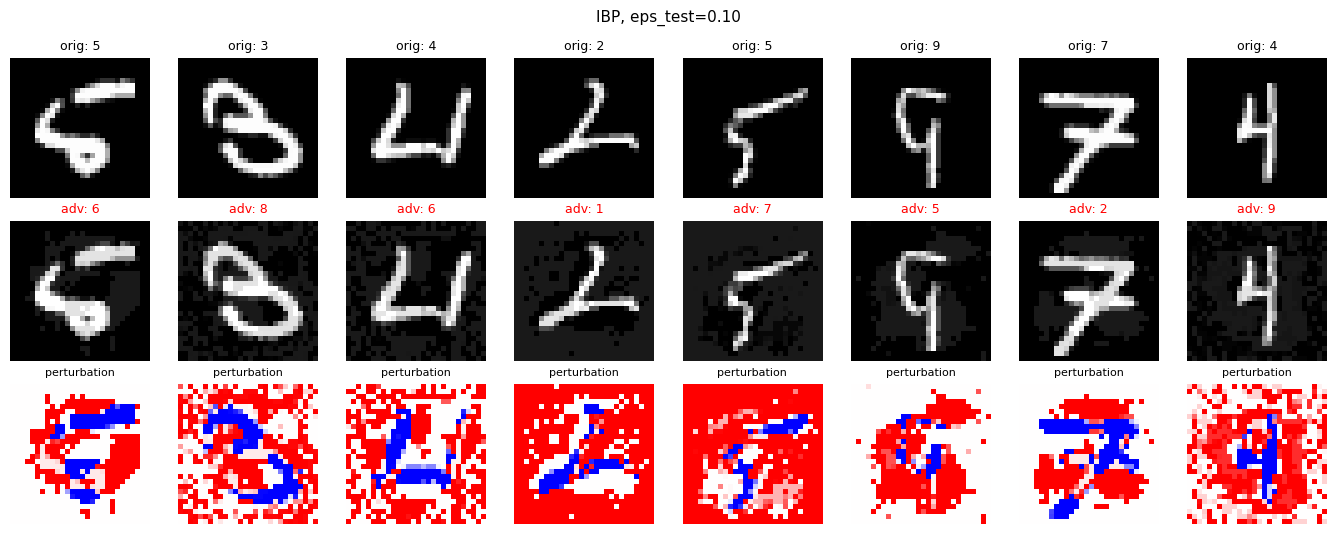

In [12]:
@torch.no_grad()
def _pred(model, x): return model(x).argmax(1)

def analyse_ball(model, name, eps, n_show=8, seed=0):
    torch.manual_seed(seed); model.eval()
    vm = verified_mask(model, Xte, Yte, eps)
    correct = _pred(model, Xte) == Yte
    cand = (correct & ~vm).nonzero().flatten()
    xa = torch.cat([pgd_attack(model, Xte[cand[i:i+1000]], Yte[cand[i:i+1000]], eps, steps=100, restarts=3) for i in range(0, len(cand), 1000)])
    pa = _pred(model, xa); y = Yte[cand]
    broken = pa != y
    n_adv, n_unk = int(broken.sum()), int((~broken).sum())
    print(f'[{name}] eps={eps:.2f}: verified {int(vm.sum())}, misclassified already {int((~correct).sum())}, '
          f'correct but not verified {len(cand)} -> PGD finds adversarial examples for {n_adv}, unknown (no attack found) for {n_unk}')
    pairs = Counter((int(a), int(b)) for a, b in zip(y[broken].tolist(), pa[broken].tolist()))
    print('   most common (true -> predicted):', pairs.most_common(5))
    linf = (xa - Xte[cand]).abs().flatten(1).max(1).values[broken]
    if n_adv:
        print(f'   mean l_inf size of the found perturbations: {linf.mean():.4f}  mean l2: {(xa - Xte[cand]).flatten(1).norm(dim=1)[broken].mean():.3f}')
    sel = broken.nonzero().flatten()[:n_show]
    if len(sel) == 0:
        return None
    fig, ax = plt.subplots(3, len(sel), figsize=(1.7 * len(sel), 5.4), squeeze=False)
    for k, j in enumerate(sel.tolist()):
        x0, x1 = Xte[cand[j]], xa[j]
        ax[0, k].imshow(x0[0].cpu(), cmap='gray', vmin=0, vmax=1); ax[0, k].set_title(f'orig: {int(y[j])}', fontsize=9)
        ax[1, k].imshow(x1[0].cpu(), cmap='gray', vmin=0, vmax=1); ax[1, k].set_title(f'adv: {int(pa[j])}', fontsize=9, color='red')
        ax[2, k].imshow((x1 - x0)[0].cpu(), cmap='bwr', vmin=-eps, vmax=eps); ax[2, k].set_title('perturbation', fontsize=8)
        for r in range(3): ax[r, k].axis('off')
    fig.suptitle(f'{name}, eps_test={eps:.2f}', fontsize=11)
    plt.tight_layout(); plt.savefig(f'adv_{name}_{eps:.2f}.png', dpi=150); plt.show()

analyse_ball(ibp_model, 'IBP', 0.1)

[IBP] eps=0.05: verified 9013, misclassified already 513, correct but not verified 474 -> PGD finds adversarial examples for 398, unknown (no attack found) for 76
   most common (true -> predicted): [((4, 9), 23), ((3, 5), 19), ((8, 2), 17), ((5, 3), 16), ((3, 2), 15)]
   mean l_inf size of the found perturbations: 0.0500  mean l2: 1.042


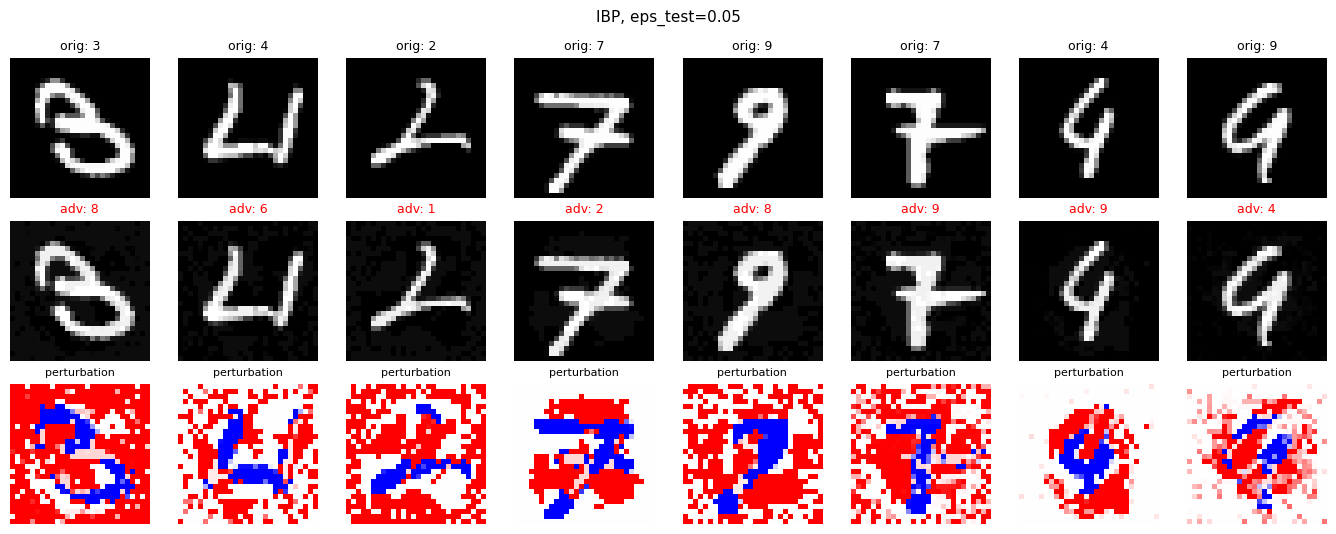

[standard] eps=0.02: verified 0, misclassified already 214, correct but not verified 9786 -> PGD finds adversarial examples for 715, unknown (no attack found) for 9071
   most common (true -> predicted): [((4, 9), 54), ((5, 3), 49), ((9, 4), 37), ((8, 3), 34), ((9, 8), 26)]
   mean l_inf size of the found perturbations: 0.0200  mean l2: 0.416


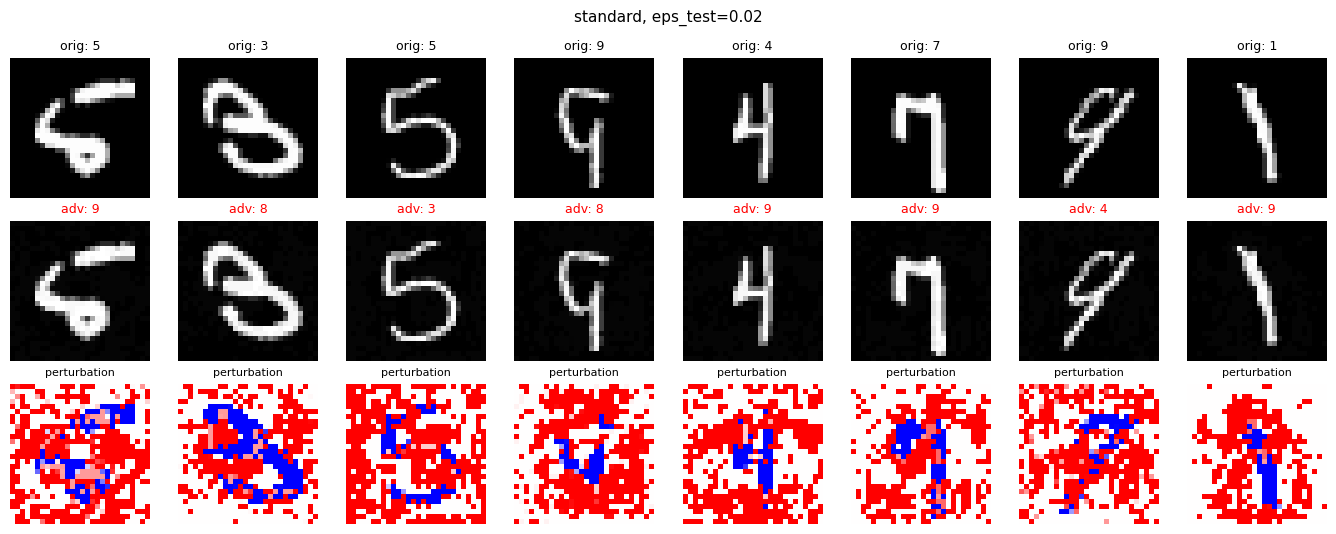

[standard] eps=0.10: verified 0, misclassified already 214, correct but not verified 9786 -> PGD finds adversarial examples for 9083, unknown (no attack found) for 703
   most common (true -> predicted): [((1, 7), 549), ((5, 3), 500), ((4, 9), 477), ((3, 5), 466), ((9, 4), 419)]
   mean l_inf size of the found perturbations: 0.1000  mean l2: 1.992


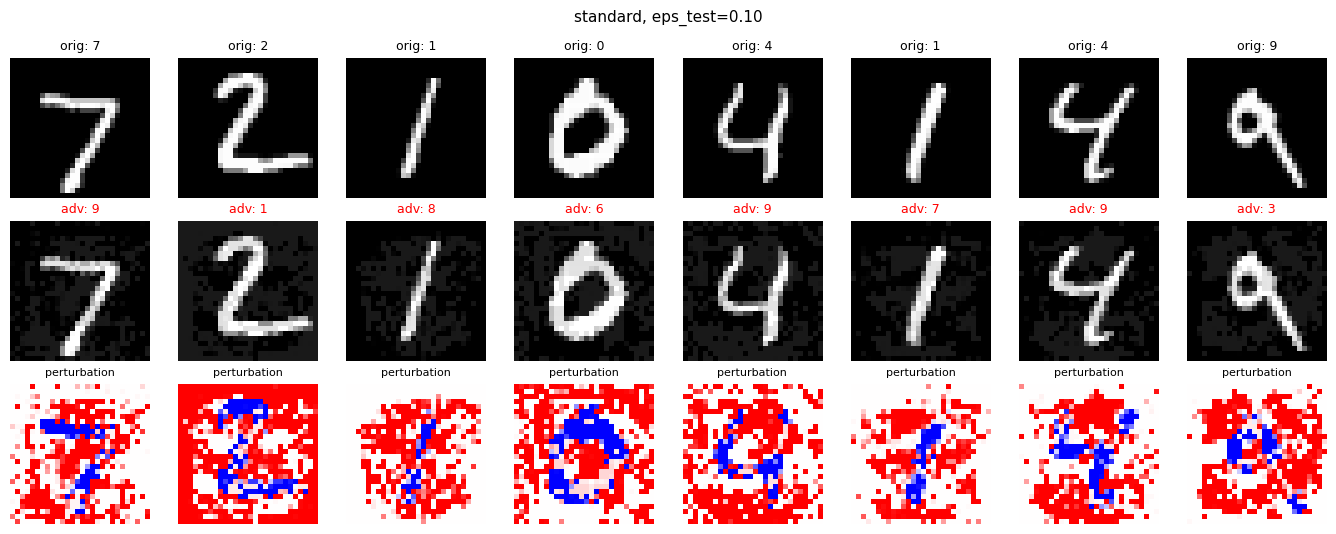

In [13]:
analyse_ball(ibp_model, 'IBP', 0.05)
analyse_ball(std_model, 'standard', 0.02)
analyse_ball(std_model, 'standard', 0.1)

## Observations

*(to be filled in after the run, from the printed numbers above)*